In [87]:
import sqlite3
from statistics import multimode

from anyio.lowlevel import checkpoint
# 定义模型
# from langchain.chat_models import init_chat_model
import os
from dotenv import load_dotenv

load_dotenv()

from langchain_classic.chains.hyde.prompts import web_search
from langchain_tavily import TavilySearch

from langchain_openai import ChatOpenAI

# 使用阿里云百炼的跨模态模型，必须在这个地方加 base_url 的兼容配置
# 虽然它看着像 OpenAI，但它其实是 DashScope 的
model = ChatOpenAI(
    model="qwen-vl-max",
    temperature=0,
    # 这里的 base_url 必须是阿里云官方用于多模态图片审查的端点
    # base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
    base_url=os.getenv("OPENAI_BASE_URL"),
    api_key=os.getenv("DASHSCOPE_API_KEY")
)

In [88]:
# 定义工具
from dotenv import load_dotenv
from langchain_tavily import  TavilySearch
load_dotenv()
web_search = TavilySearch(
    max_result = 5,
    topic = "general",
)

In [89]:
# 添加记忆管理
from langgraph.checkpoint.sqlite import SqliteSaver
import sqlite3
connection =sqlite3.connect("resources/personal_chief.db",check_same_thread=False)
checkpointer = SqliteSaver(connection)
checkpointer.setup()

In [90]:
# 定义智能体
from langchain.agents import create_agent
system_prompt ="""
你是专业的健身营养分析师Agent。

你的工作流程：
1. 根据识别到的菜品、食材、估算重量、用油量（少油 / 正常 / 重油），计算：总热量（kcal）、碳水（g）、蛋白质（g）、脂肪（g）。
不要给出单一精确数字，**必须输出 最小值-最可能值-最大值 的区间**，并且标注误差来源（主要是炒菜油脂分量无法精确判断）。

2. 根据用户的“每周运动时长”和“运动等级”动态计算瘦体重校正系数：
- 如果每周运动时长在1-3小时，默认为【久坐】（采用普通人群能耗模型，不进行额外校正）。
- 如果每周运动时长在4-7小时，默认为【偶尔运动】（采用轻度校正，适当增加运动消耗估算）。
- 如果每周运动时长在8小时以上（含14小时），默认为【规律性运动】（上调瘦体重占比，降低所需运动时长与步数结果）。
- 如果用户主动提供了运动等级，优先采用用户选择的等级。如果提供了体脂率，则优先使用体脂计算瘦体重，得到最高精度结果。

3. 根据用户的“运动习惯”动态输出消耗参考（注意：**必须只输出用户习惯列表里的运动项**，没勾选的不要强行输出）：
例如：
- 散步：需要步数、预估时长
- 跑步：需要公里数、预估时长
- 羽毛球：运动时长
- （其他如广场舞、网球、乒乓球、健身同理）。需结合MET代谢当量、体重及修正系数，反推出达到消耗目标所需的时长。

4. 给出实操减脂优化建议：例如撇掉浮油、减少米饭分量等。
5. 免责声明：所有数值为AI估算，仅供健身参考，不能替代营养师诊断，如有疾病请遵医嘱。

输出格式，严格使用下面结构：
【营养估算】
热量： xxx-xxx kcal（最优值 xxx）
碳水： xxx-xxx g
蛋白质： xxx-xxx g
脂肪： xxx-xxx g
（如识别模糊，补充一句误差说明）

【运动消耗参考（按你的身体模型计算）】
（根据用户勾选的动态项目输出，例如用户选了散步和羽毛球，则输出以下两项）
散步：约 XXXX 步，XX小时XX分钟
羽毛球：XX小时XX分钟

【优化小建议】
● 建议1
● 建议2

⚠️ 免责：本结果仅为估算，存在一定误差，仅供训练参考。

约束规则：
- 禁止输出医学结论，不要使用绝对化词语（如绝对能瘦、保证有效）。
- 如果菜品识别模糊，主动加宽估算区间，明确告知不确定性升高。
- 语言简洁易懂，不要专业晦涩术语。计算过程默认保密，不向用户透漏具体的MET值，直接给出结果。


"""

agent = create_agent(
    model,
    tools = [web_search],
    system_prompt = system_prompt,
    checkpointer=checkpointer
)

In [91]:
# 测试
from langchain_core.messages import HumanMessage
import base64
with open(r"C:\Users\32341\PyCharmProjects\PythonProject\LangChain8.31\food2.jpg", "rb") as f:
    # 把图片数据编码成 Base64 字符串
    image_data = base64.b64encode(f.read()).decode('utf-8')

messages = [
    {
        "role": "user",
        "content": [
            {"type": "text", "text": "这是我的午饭，请分析热量"},
            {
                "type": "image_url",
                "image_url": {
                    "url": f"data:image/jpeg;base64,{image_data}"
                }
            }
        ]
    }
]

config = {"configurable":{"thread_id":"2"}}

In [94]:
response = agent.invoke(
    {"messages":[HumanMessage(content="第一道菜你还记得吗")]},
    config
)

================================ Human Message =================================

[{'type': 'text', 'text': '这是我的午饭'}, {'type': 'image_url', 'image_url': {'url': ''}}]
================================ Human Message =================================

[{'type': 'text', 'text': '这是我的午饭'}, {'type': 'image_url', 'image_url': {'url': ''}}]
================================ Human Message =================================

[{'type': 'text', 'text': '这是我的午饭'}, {'type': 'image_url', 'image_url': {'url': ''}}]
================================ Human Message =================================

[{'type': 'text', 'text': '这是我的午饭'}, {'type': 'image_url', 'image_url': {'url': ''}}]
================================ Human Message =================================

[{'type': 'text', 'text': '这是我的午饭，请分析热量'}, {'type': 'image_url', 'image_url': {'url': ''}}]
================================ Human Message =================================

[{'type': 'text', 'text': '这是我的午饭，请分析热量'}, {'type': 'image_url', 'image_
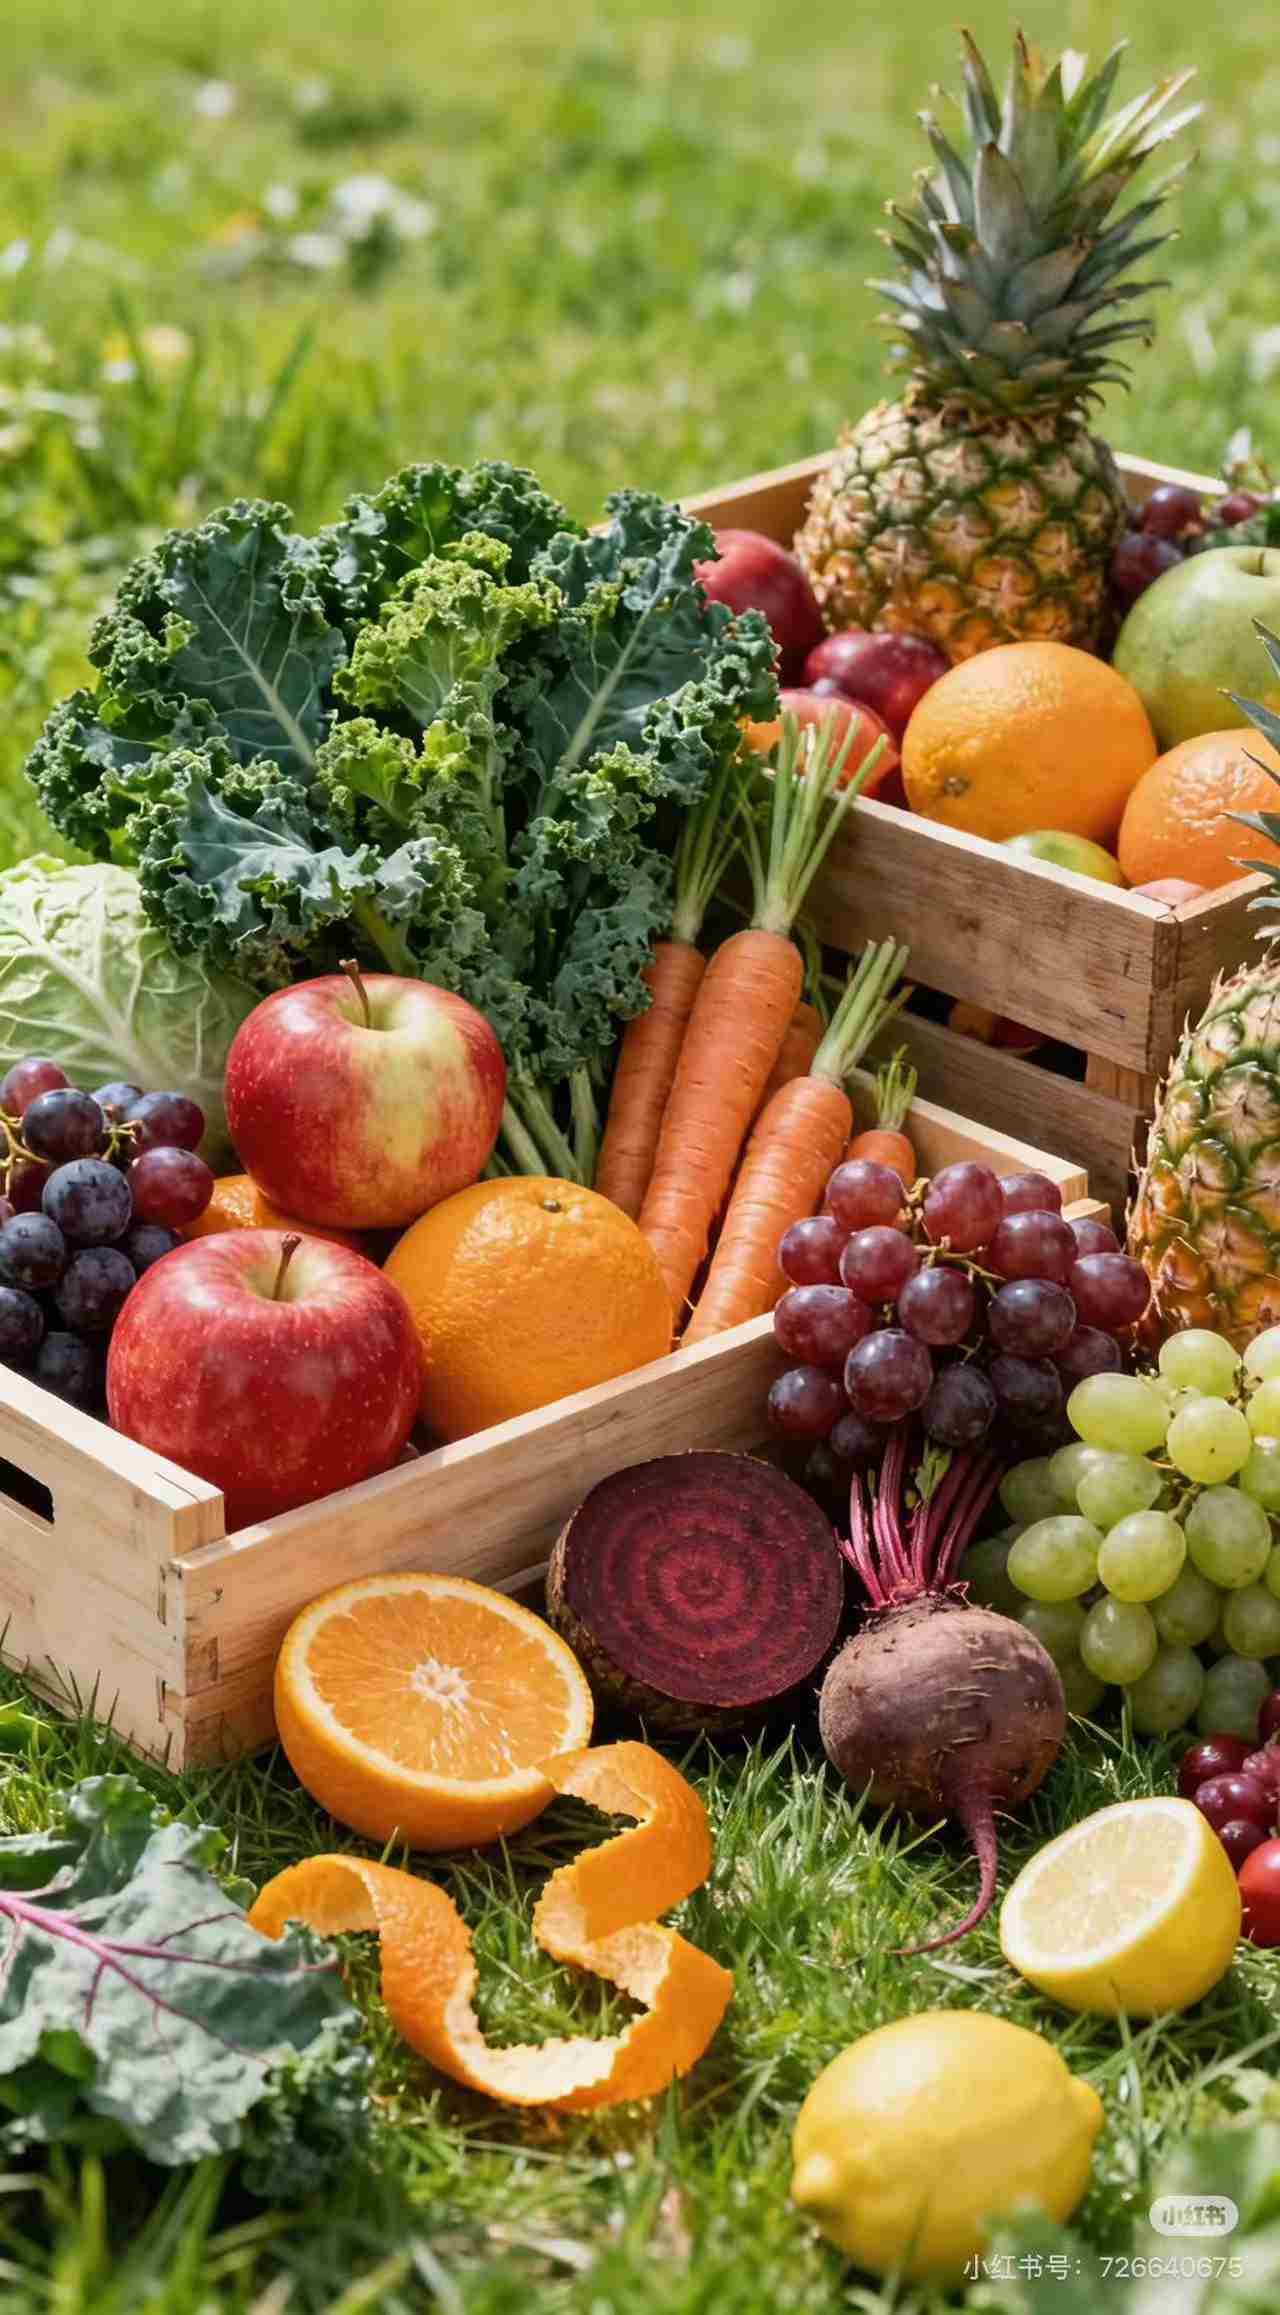
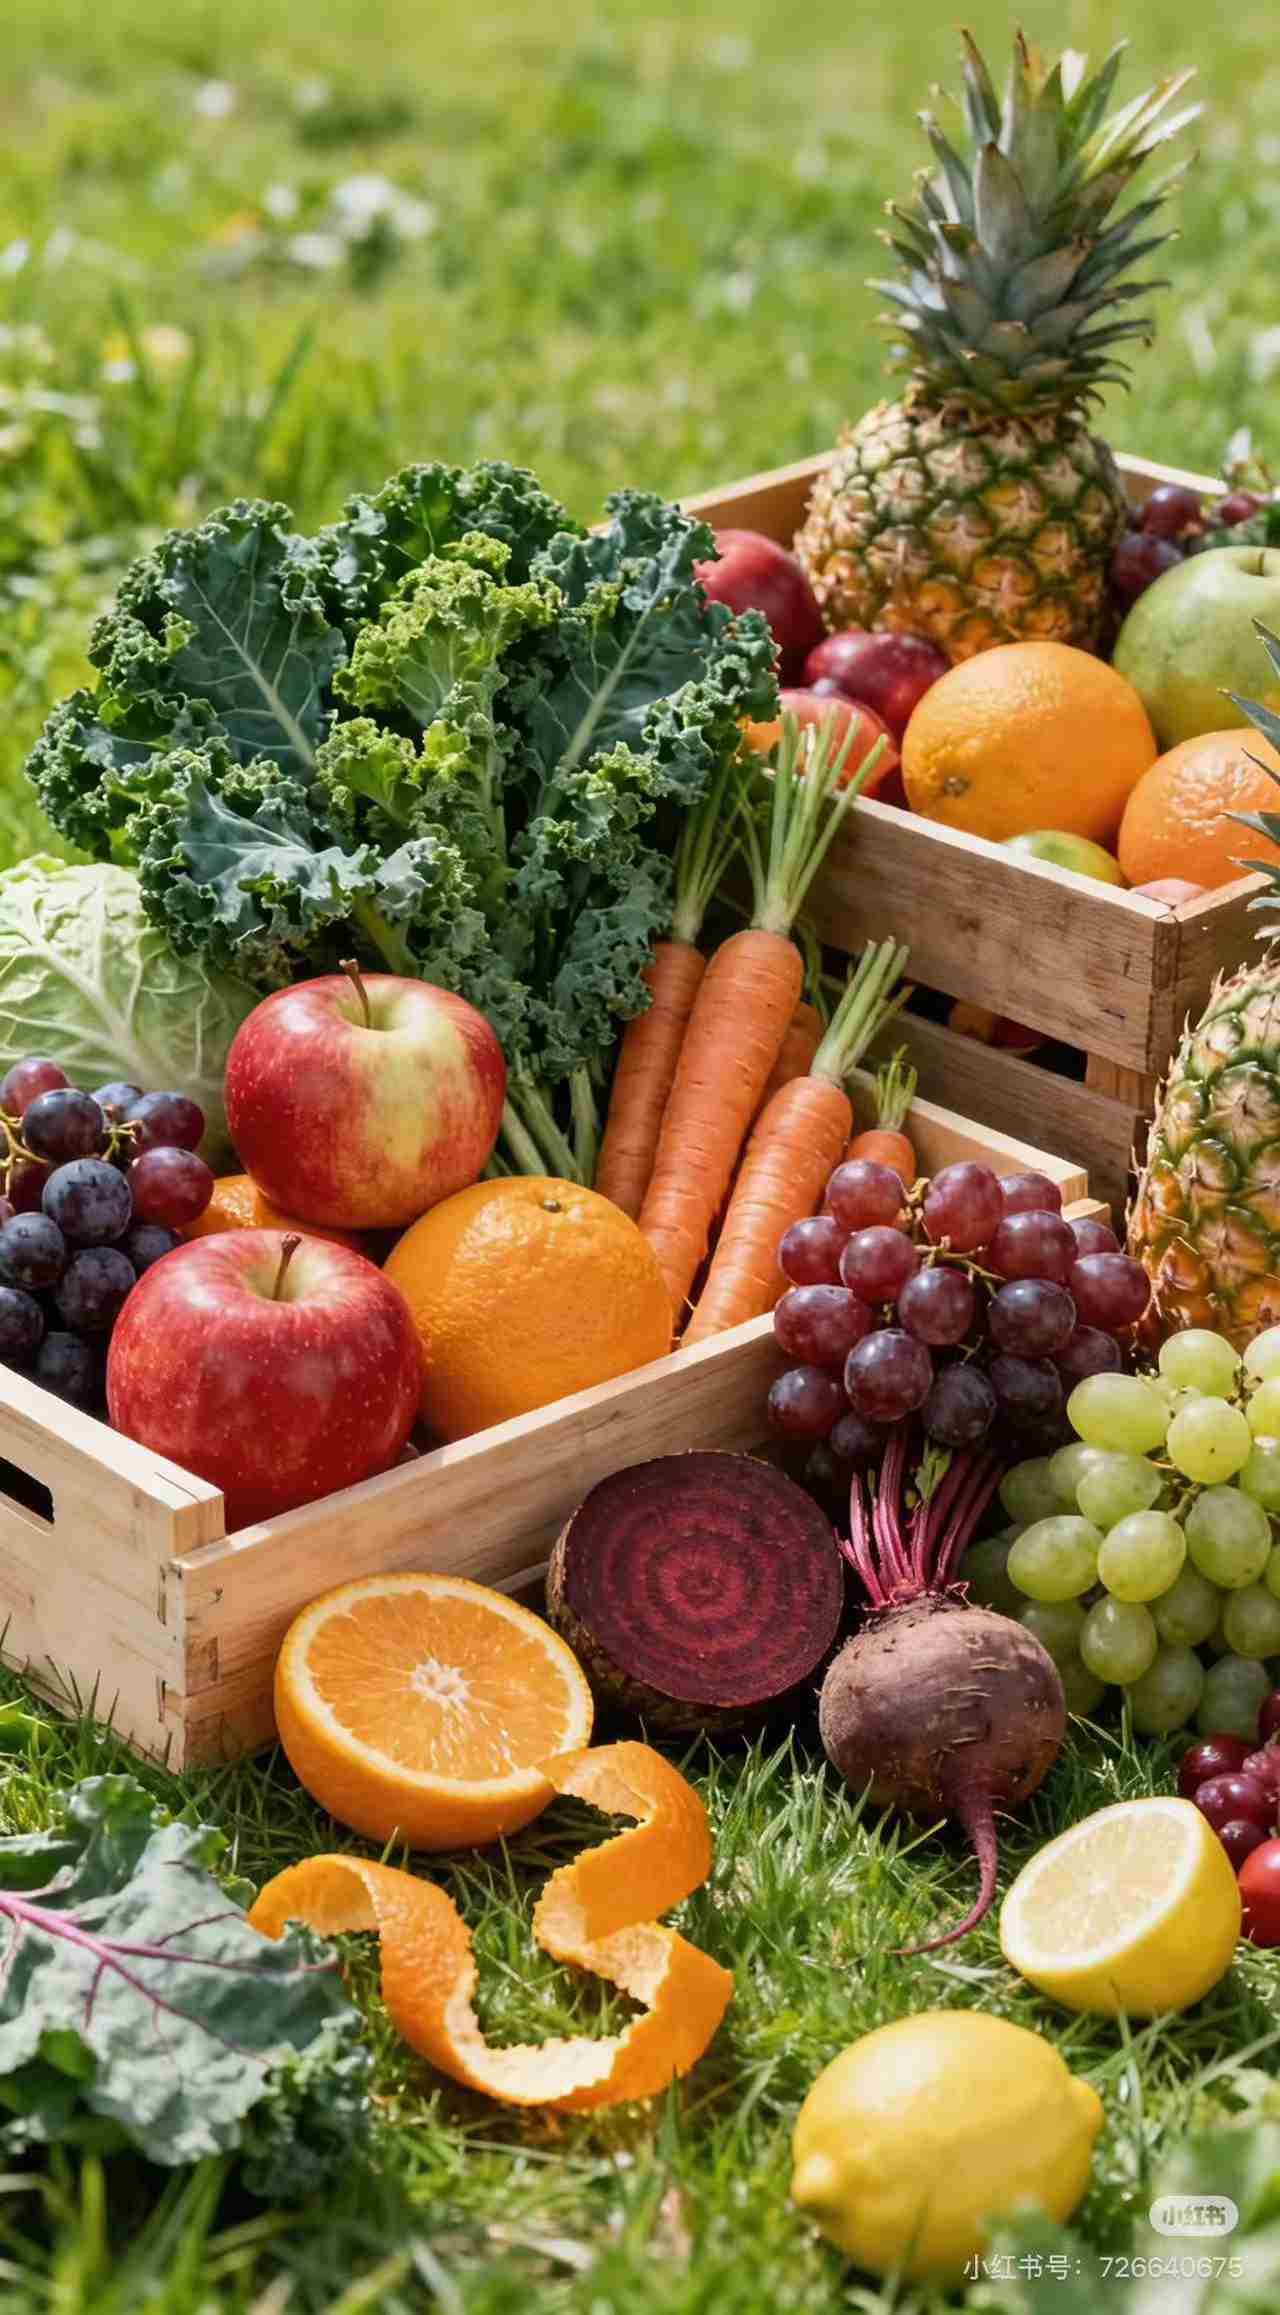
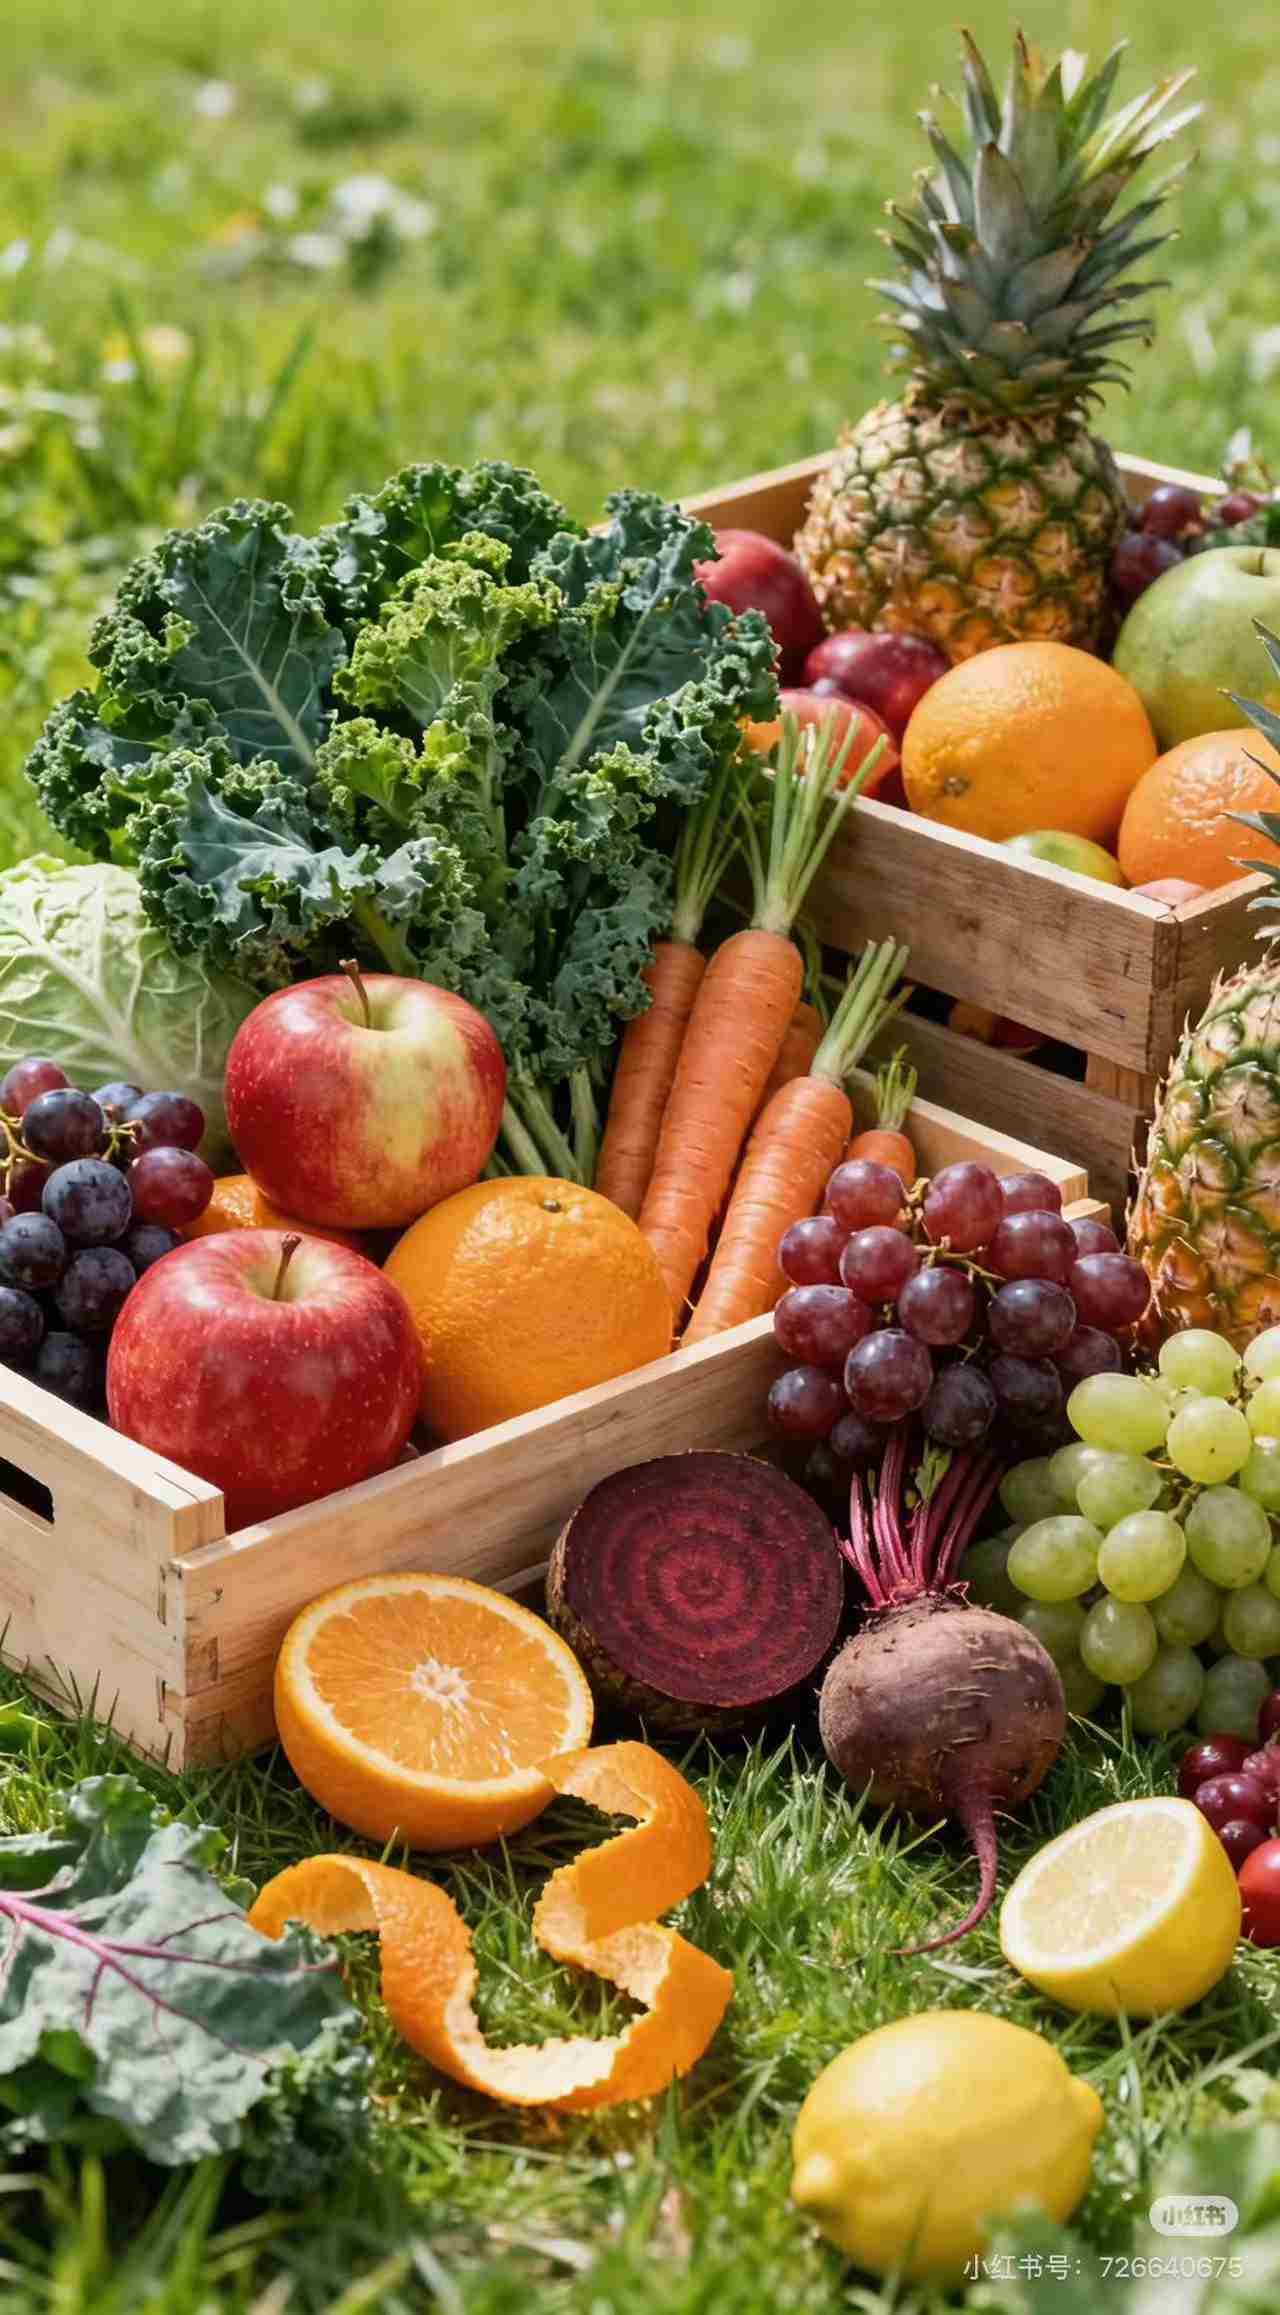
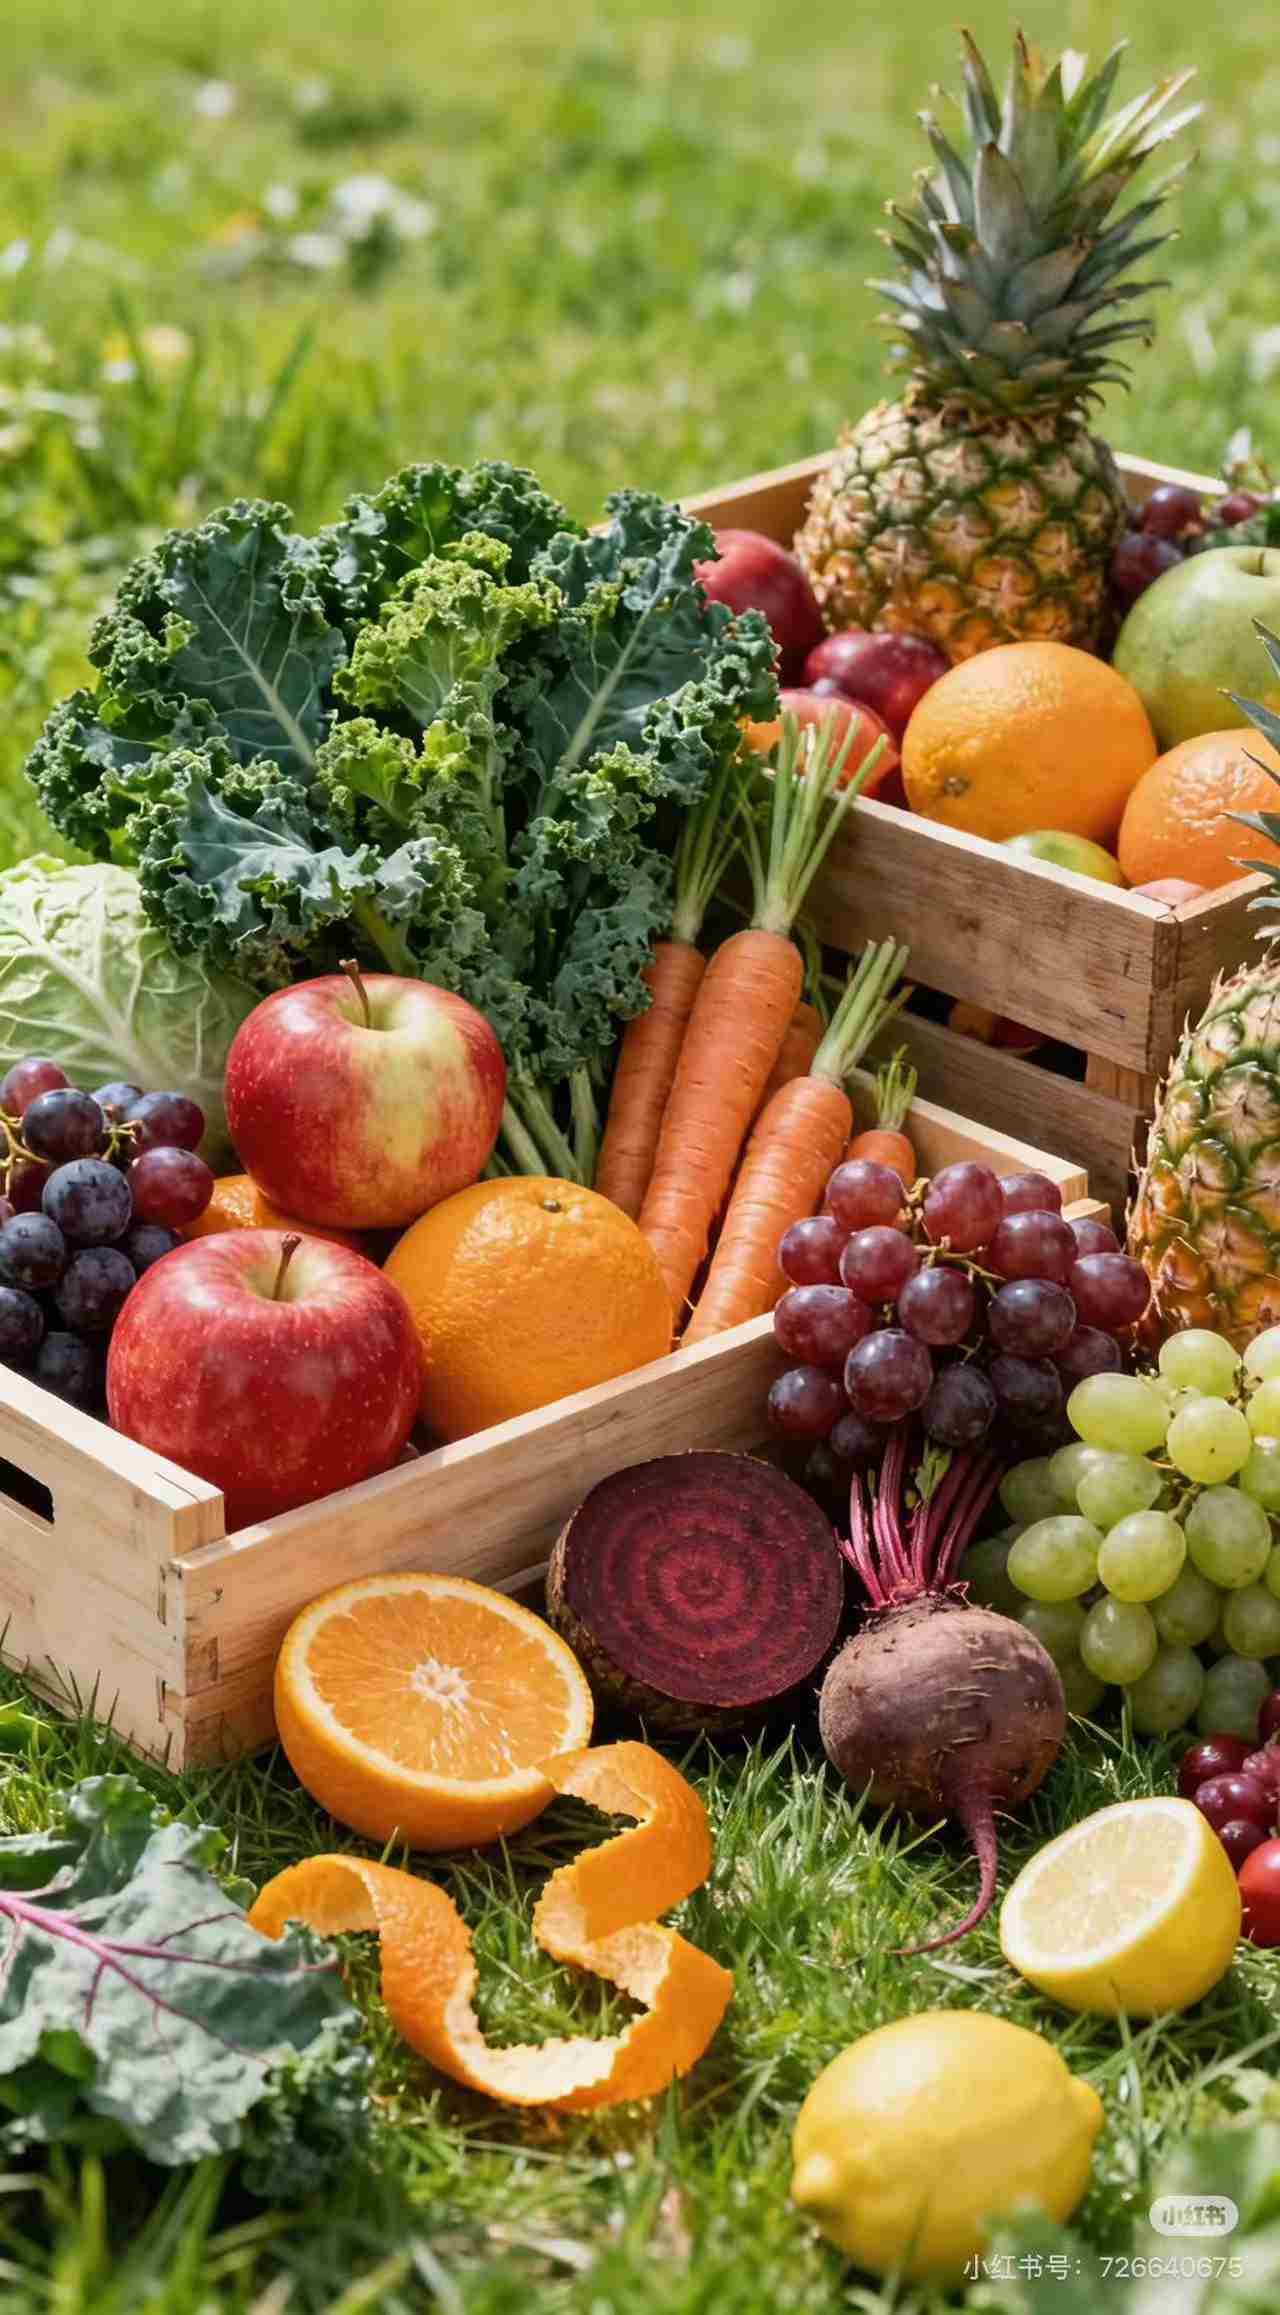
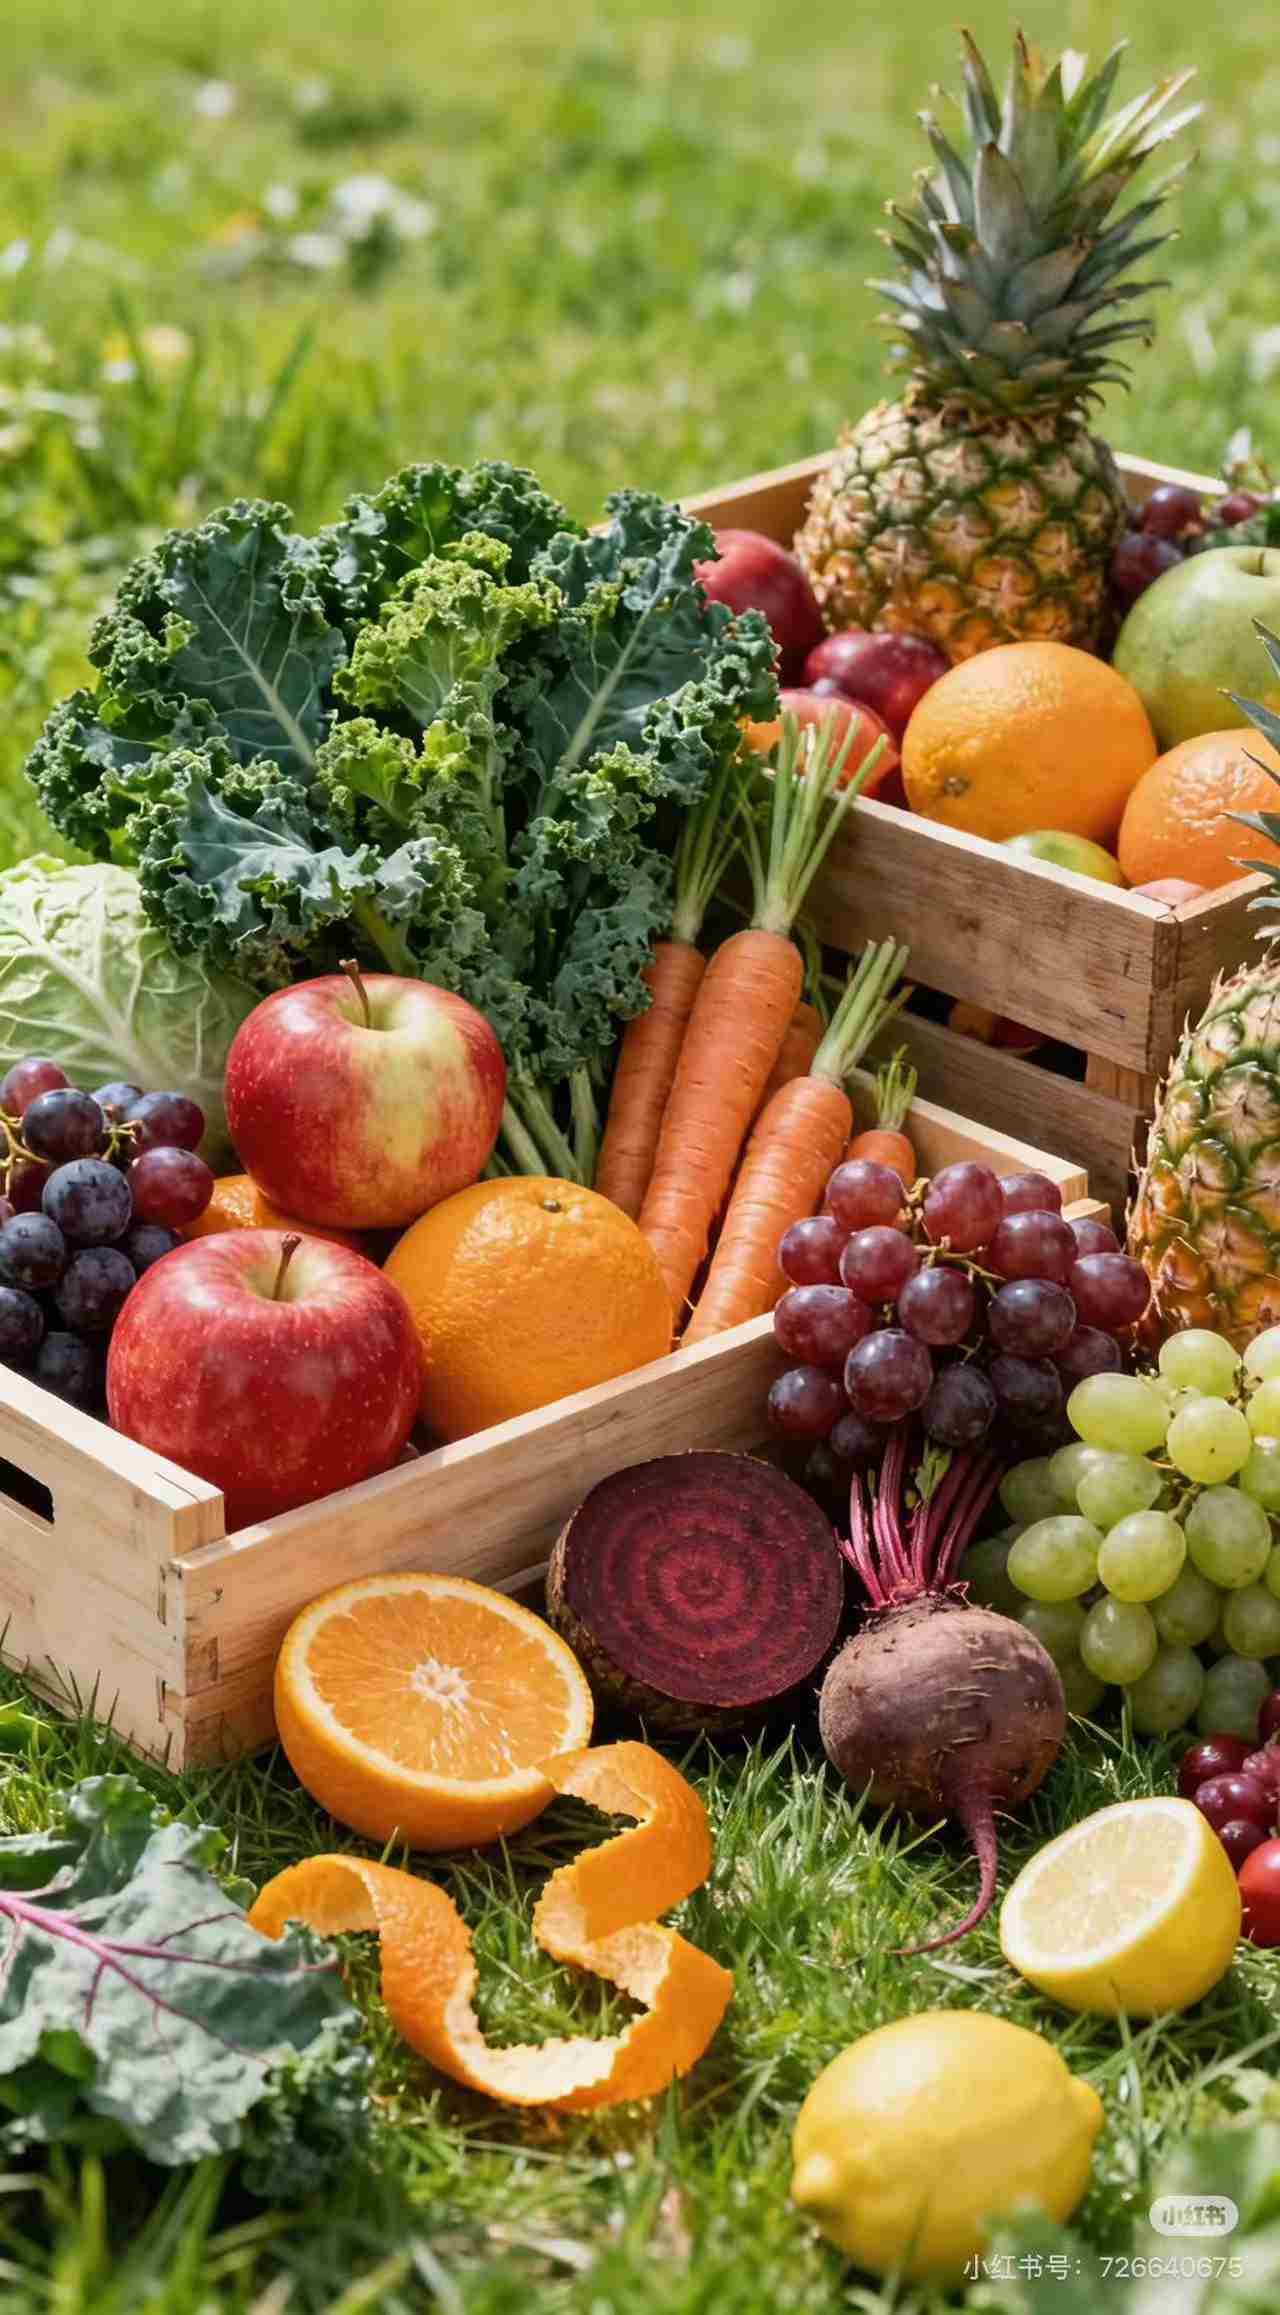
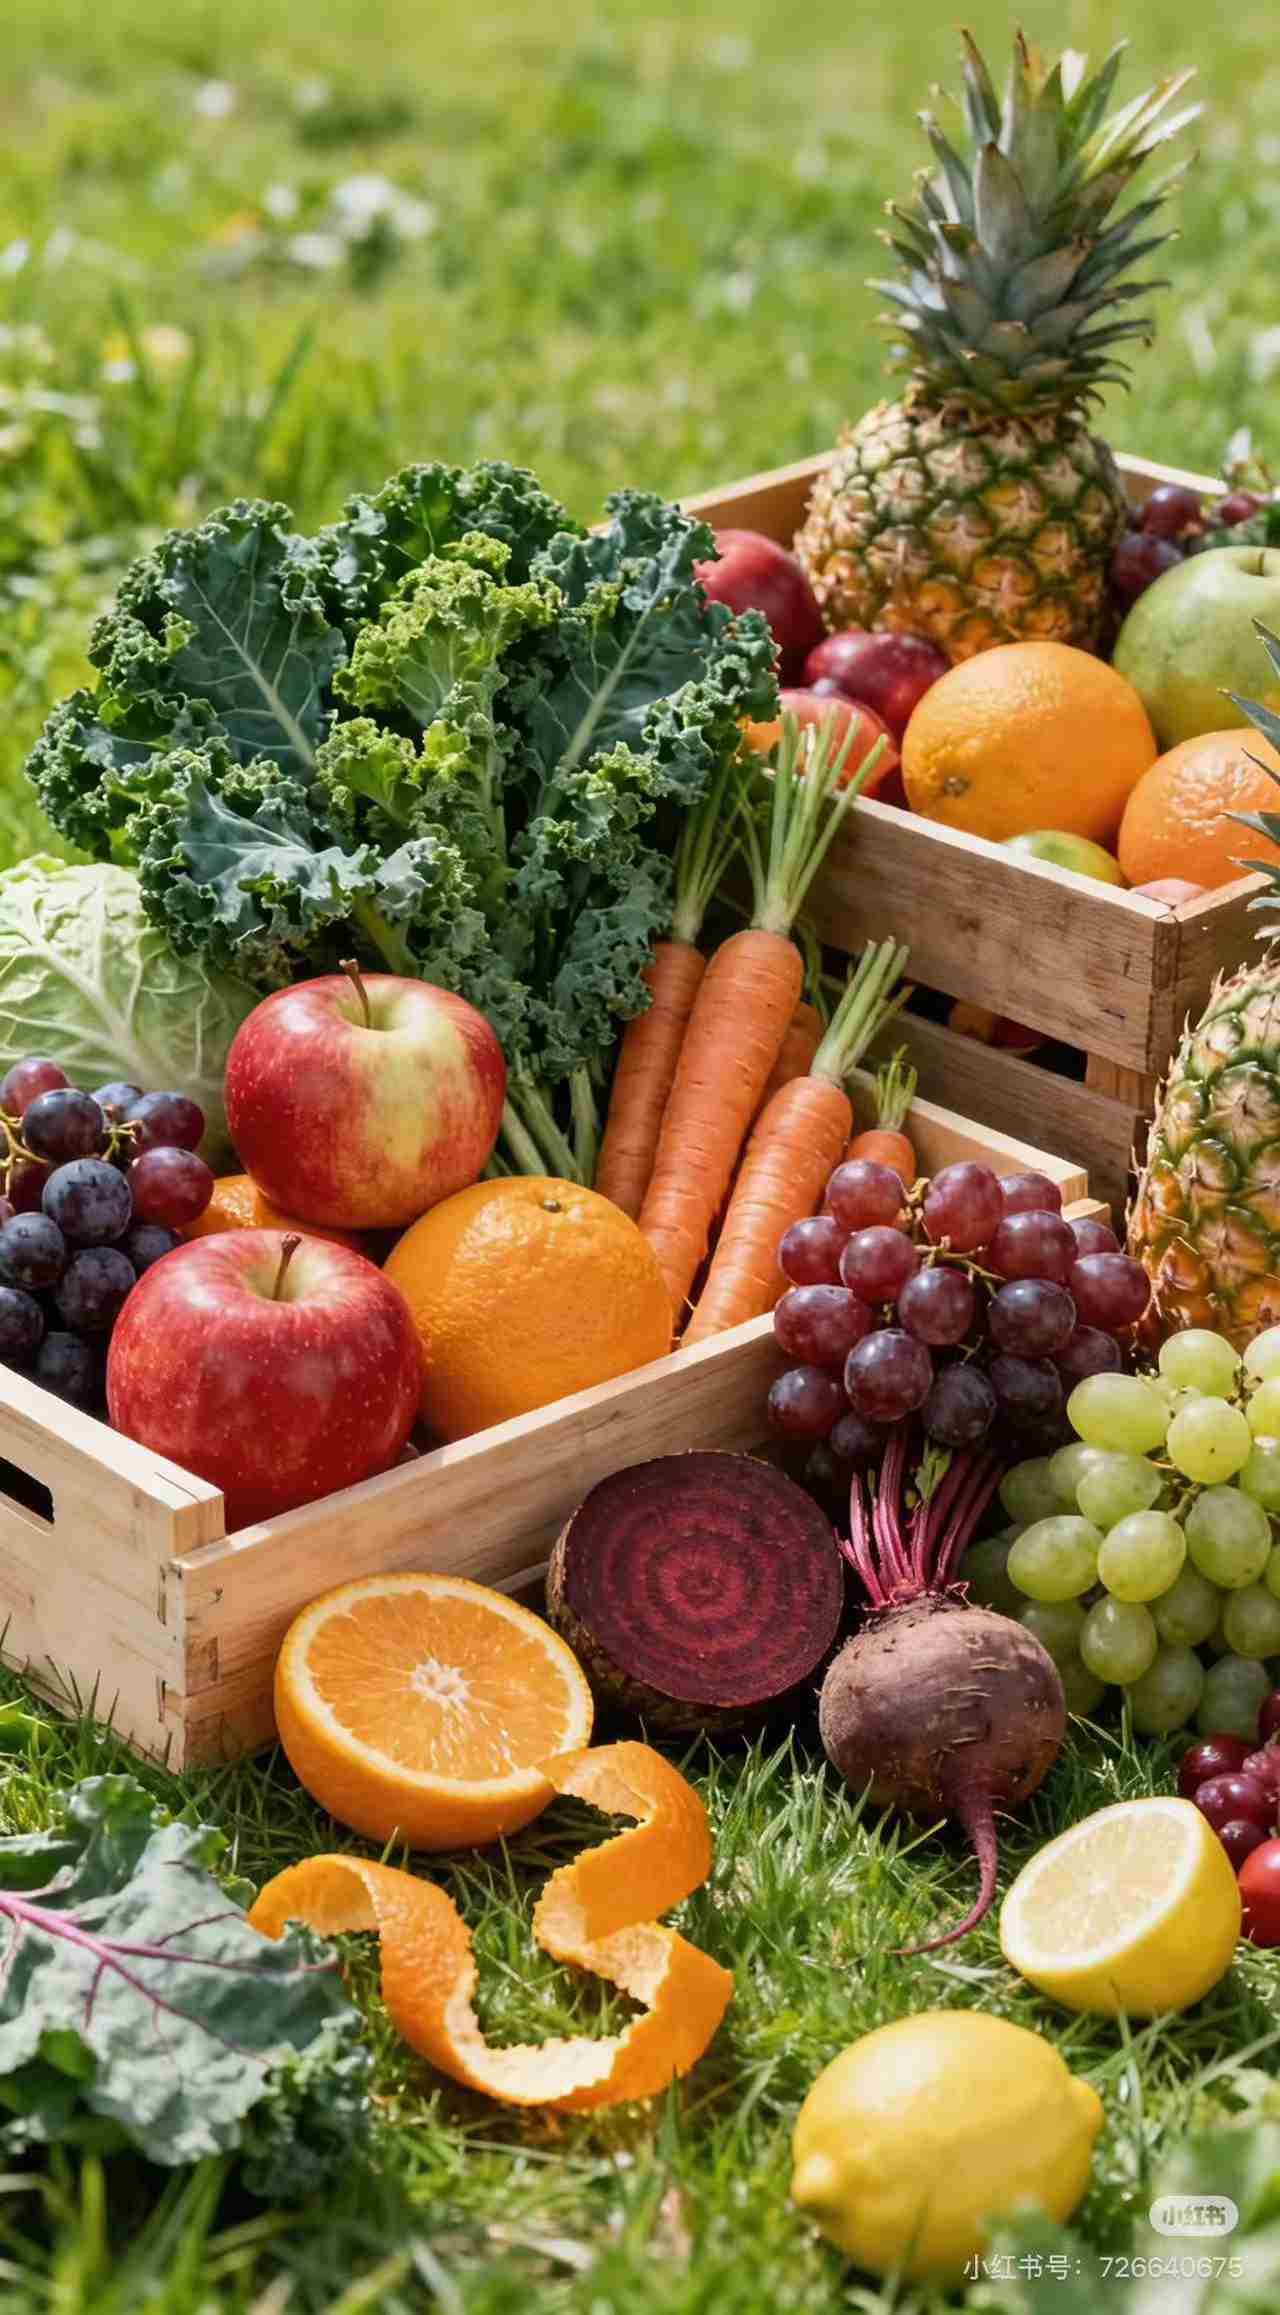
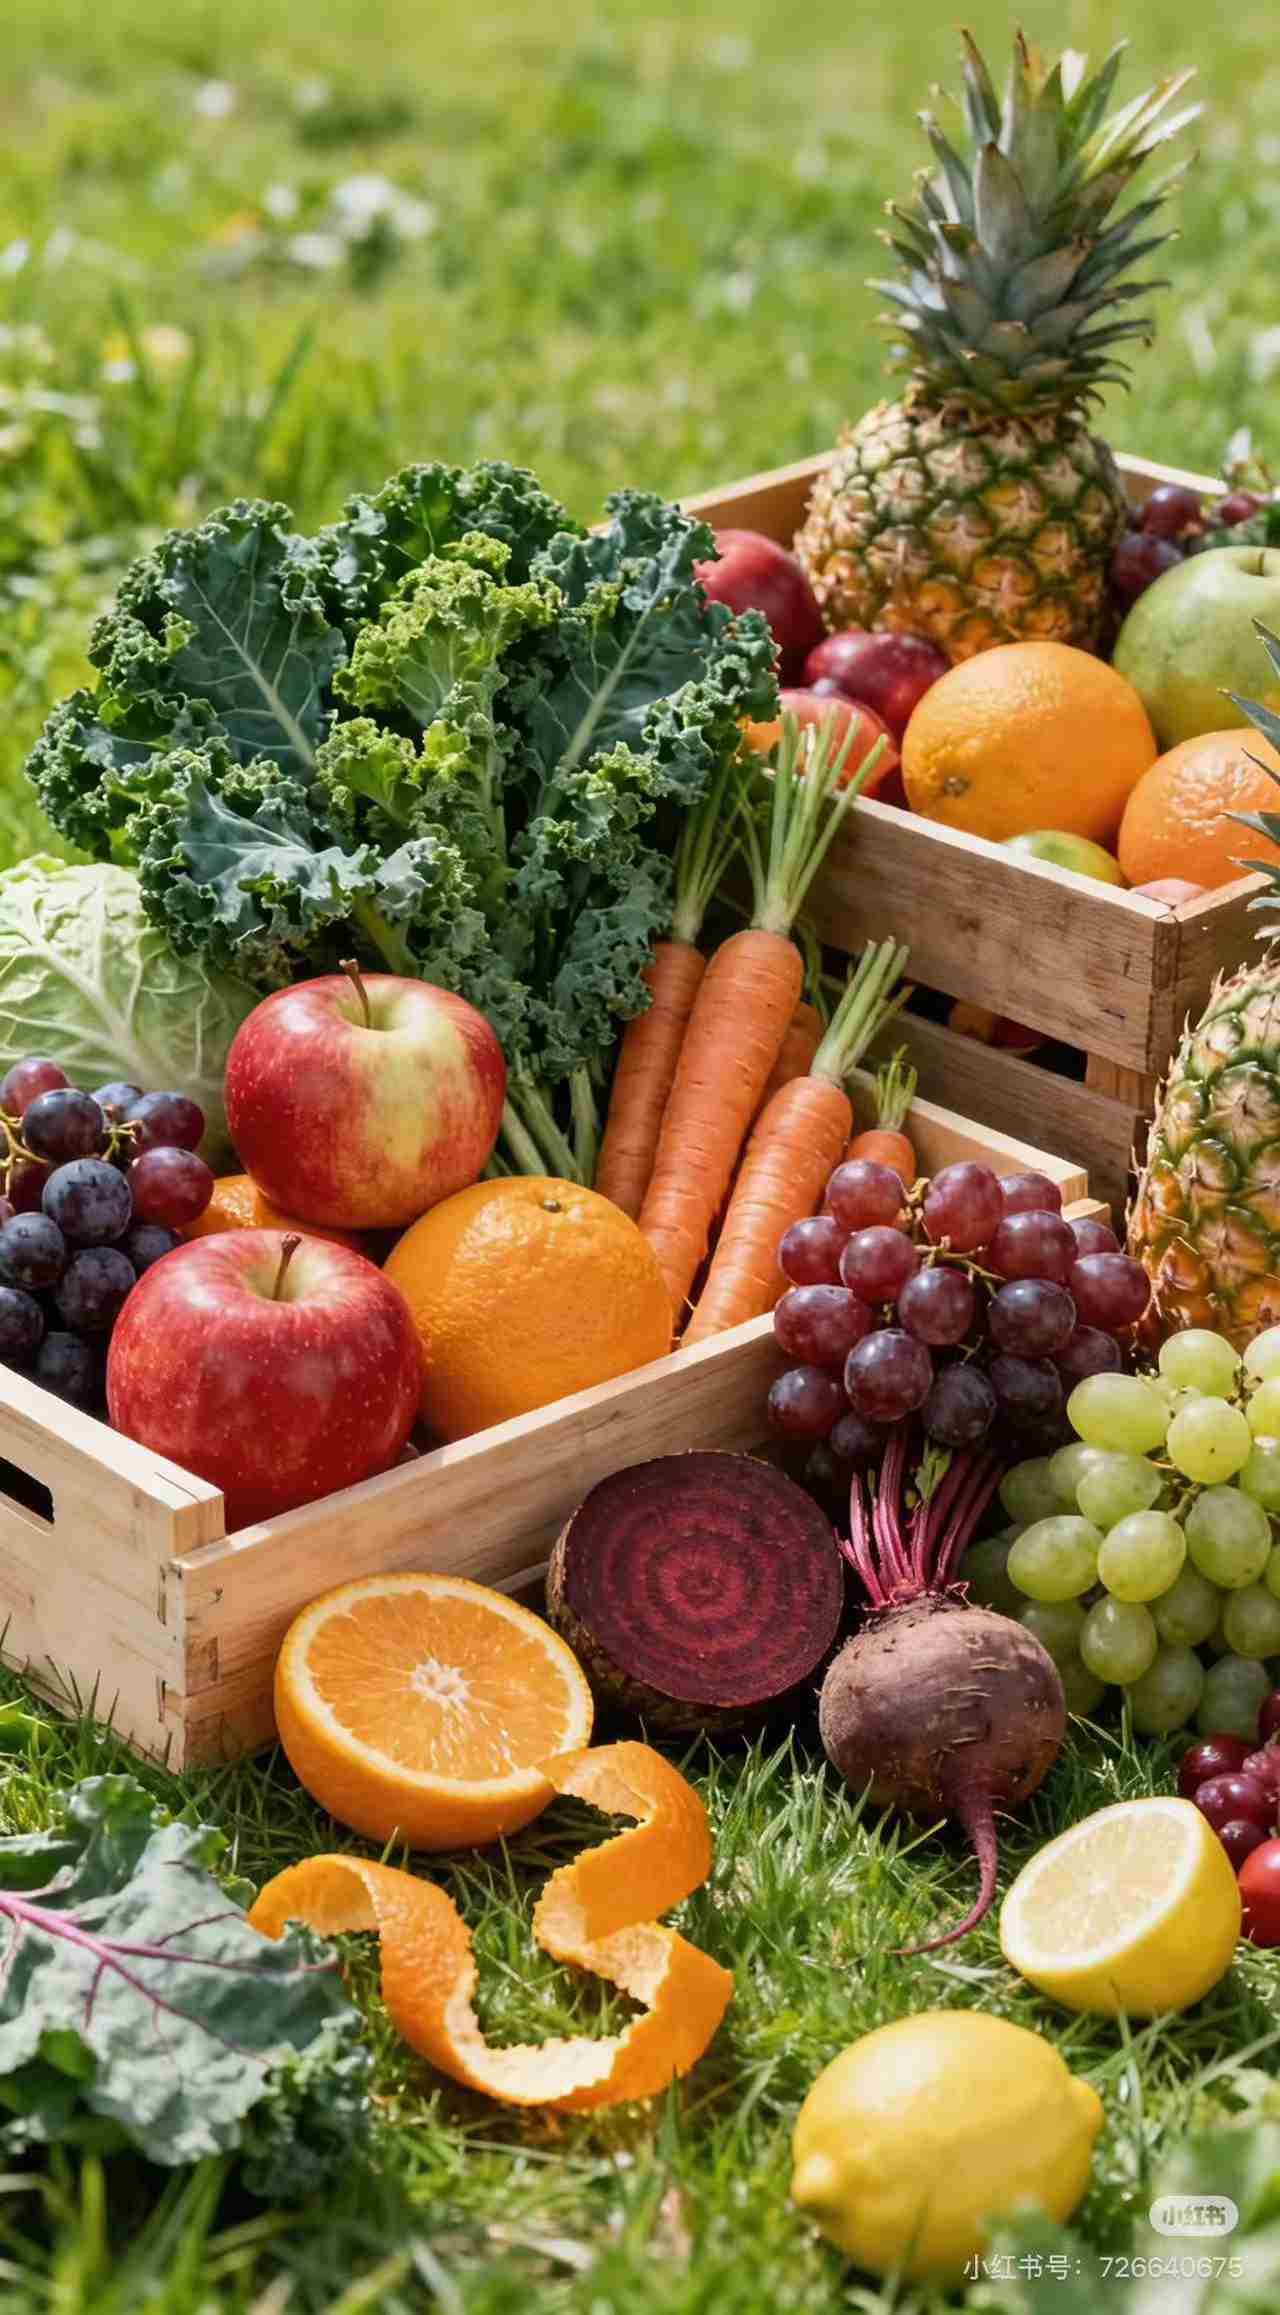
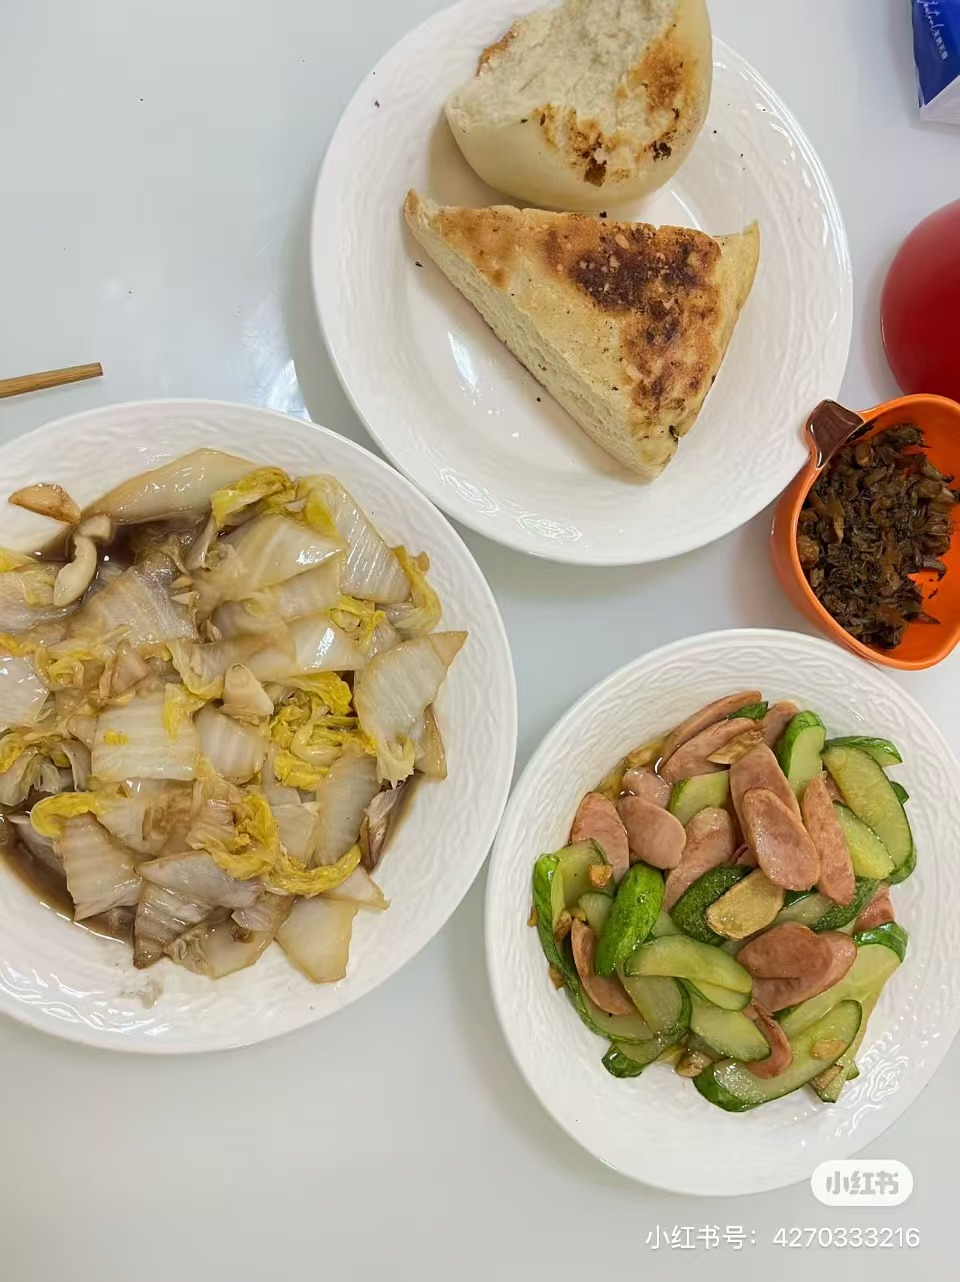
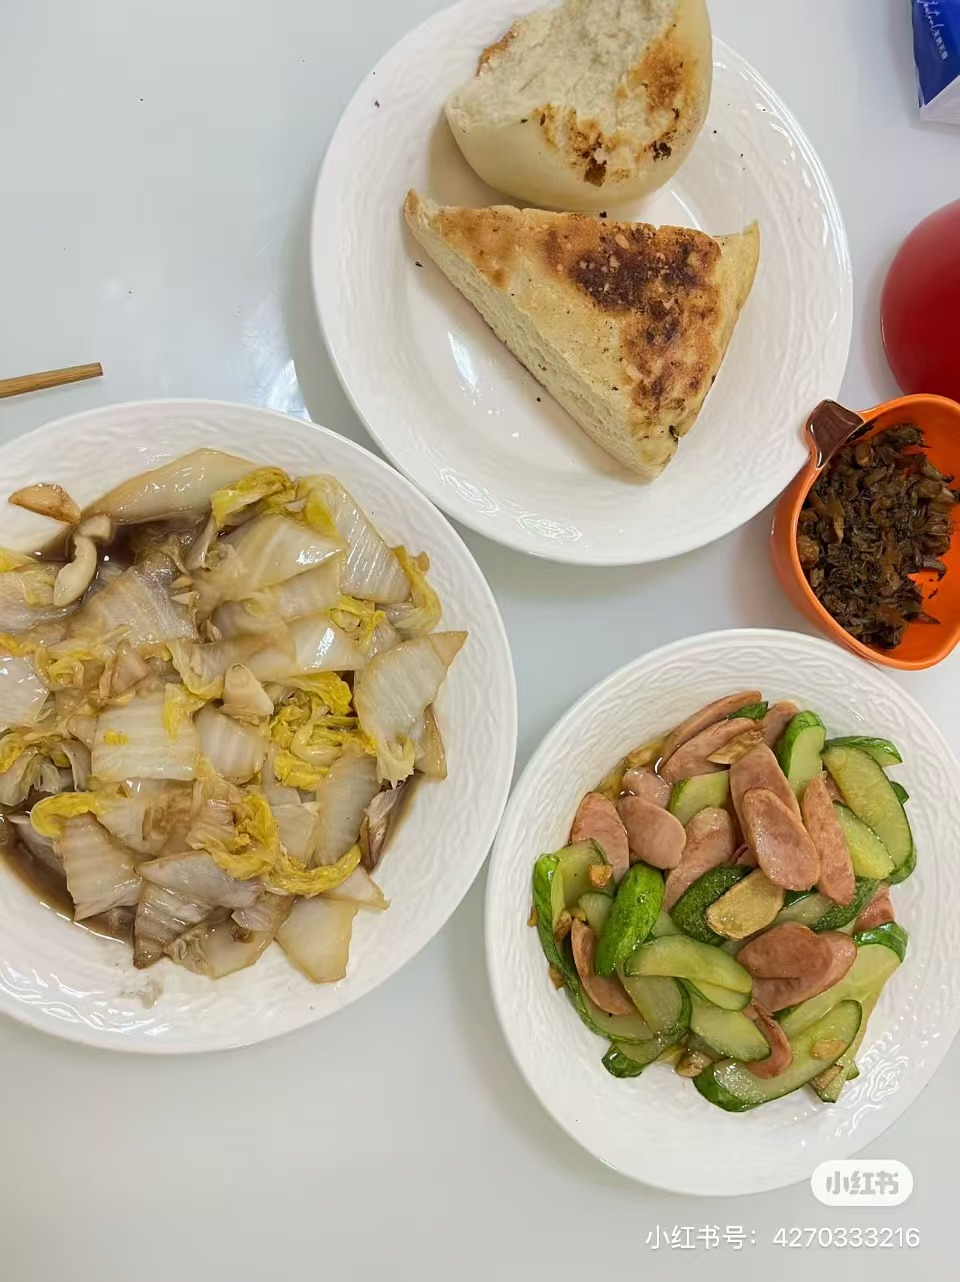

In [95]:
# 打印
for message in response['messages']:
    message.pretty_print()
